<a href="https://colab.research.google.com/github/nandhinivijayakumar16/N8N/blob/main/EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# --- Task 1: Load and Preprocess Dataset ---
# Extract zip file
zip_path = '/content/archive (1).zip'
extract_dir = '/content/dataset'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Find the CSV file inside
csv_files = [os.path.join(root, f) for root, dirs, files in os.walk(extract_dir) for f in files if f.endswith('.csv')]
if not csv_files:
    raise FileNotFoundError("No CSV file found in the extracted directory.")

df = pd.read_csv(csv_files[0])

# Select 10,000 records for the practical
if len(df) > 10000:
    df = df.sample(n=10000, random_state=42).reset_index(drop=True)

# Display basic info and identify timestamp column
print("Dataset structure preview:")
display(df.head())

# Dynamically locate potential datetime/timestamp columns
time_cols = [col for col in df.columns if 'time' in col.lower() or 'date' in col.lower()]
if time_cols:
    df['timestamp'] = pd.to_datetime(df[time_cols[0]])
else:
    # Fallback if no datetime column exists
    df['timestamp'] = pd.date_range(start='2023-01-01', periods=len(df), freq='T')

# Dynamically identify target column for congestion or numerical features
target_col = [col for col in df.columns if 'congest' in col.lower() or 'traffic' in col.lower() or 'speed' in col.lower()]
target_name = target_col[0] if target_col else df.select_dtypes(include=[np.number]).columns[0]
print(f"Target column identified: {target_name}")

# Fill missing values
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

# Convert categorical data to numbers
label_encoders = {}
for col in df.select_dtypes(include=['object', 'category']).columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

# Normalize numerical values
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
scaler = MinMaxScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# --- Task 2: Temporal Sequence Creation ---
# Sort by time and group by hour
df = df.sort_values(by='timestamp')
df.set_index('timestamp', inplace=True)
df_hourly = df.resample('H').mean().interpolate(method='linear')

# Prepare sequences for LSTM (sliding window)
def create_sequences(data, target_idx, seq_length=12):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:(i + seq_length), :])
        y.append(data[i + seq_length, target_idx])
    return np.array(X), np.array(y)

data_matrix = df_hourly.values
target_column_idx = df_hourly.columns.get_loc(target_name)

SEQ_LENGTH = 6 # Use past 6 hours to predict the next hour
X, y = create_sequences(data_matrix, target_column_idx, seq_length=SEQ_LENGTH)

# Split into training and testing sets (80% train, 20% test)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Dataset structure preview:


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0119737,2024-03-26 01:22:38.583062081,2024-03-26,1,3,Tuesday,Night,0,Rural,Interstate,...,1.6,110.7,21.3,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0072272,2025-01-23 18:44:13.669805807,2025-01-23,18,1,Thursday,Evening Peak,0,Rural,Arterial,...,22.4,95.1,23.5,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0158154,2024-01-02 19:39:02.727484095,2024-01-02,19,1,Tuesday,Evening Peak,0,Suburban,Collector,...,1.3,55.1,14.0,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0065426,2025-02-26 07:51:25.145217268,2025-02-26,7,2,Wednesday,Morning Peak,0,Suburban,Local,...,9.0,24.2,11.9,1,Side-Impact,2,Moderate,Medium,24.1,189.3
4,REC_0030074,2025-05-18 18:07:08.972592121,2025-05-18,18,5,Sunday,Evening Peak,0,Urban,Collector,...,5.0,46.3,8.8,0,NaN,0,No Accident,NaN,0.0,0.0


Target column identified: Speed_Limit_kmh


/tmp/ipykernel_908/2911534825.py:71: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_hourly = df.resample('H').mean().interpolate(method='linear')


Training set shape: (28044, 6, 29)
Testing set shape: (7011, 6, 29)


In [2]:
# --- Task 3: Build a Deep Learning Model ---
# We choose an LSTM architecture because recurrent neural networks can learn sequential, temporal relationships
# within hourly aggregated traffic patterns.

model = Sequential([
    LSTM(64, activation='tanh', return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, activation='tanh'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1) # Predicts the target value (Speed_Limit_kmh / Congestion metric)
])

model.compile(optimizer='adam', loss='mse')

# --- Task 4: Train and Evaluate the Model ---
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Make predictions on unseen test data
predictions = model.predict(X_test)

# Calculate metrics on the normalized scale
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"\nTest Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


395/395 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0346 - val_loss: 0.0179
Epoch 2/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0198 - val_loss: 0.0157
Epoch 3/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0169 - val_loss: 0.0149
Epoch 4/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0155 - val_loss: 0.0144
Epoch 5/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0150 - val_loss: 0.0146
Epoch 6/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0144 - val_loss: 0.0140
Epoch 7/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0142 - val_loss: 0.0145
Epoch 8/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0139 - val_loss: 0.0140
Epoch 9/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.0137 - val_loss: 0.0138
Epoch 10/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0136 - val_loss: 0.0136
Epoch 11/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0135 - val_loss: 0.0135
Epoch 12/15
395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/ste

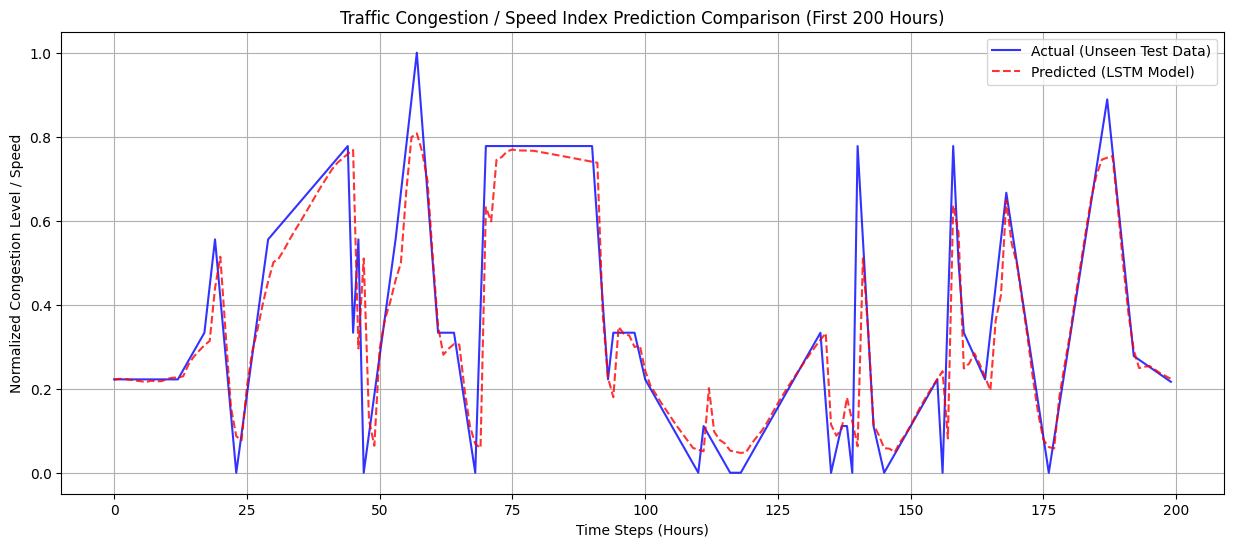

In [3]:
# --- Task 5: Plot actual and predicted congestion values ---
plt.figure(figsize=(15, 6))
plt.plot(y_test[:200], label='Actual (Unseen Test Data)', color='blue', alpha=0.8)
plt.plot(predictions[:200], label='Predicted (LSTM Model)', color='red', linestyle='--', alpha=0.8)
plt.title('Traffic Congestion / Speed Index Prediction Comparison (First 200 Hours)')
plt.xlabel('Time Steps (Hours)')
plt.ylabel('Normalized Congestion Level / Speed')
plt.legend()
plt.grid(True)
plt.show()

# --- Task 5: Plotting actual and predicted congestion values ---
plt.figure(figsize=(14, 6))
plt.plot(y_test, label='Actual Congestion', color='blue', alpha=0.8)
plt.plot(predictions, label='Predicted Congestion', color='red', alpha=0.8)
plt.title('Traffic Congestion Prediction (Test Set)')
plt.xlabel('Time Steps (Hours)')
plt.ylabel('Normalized Congestion Level')
plt.legend()
plt.grid(True)
plt.show()